# Scenario-level explanations for health-care fraud detection: results

This notebook walks through every result of the pipeline on the real data: Medicare Part B and DMEPOS provider files 2018–2024, with OIG LEIE exclusions as labels. It reads only the committed files under `outputs/`, so it runs from a fresh clone. It needs neither the 25 GB `data/` folder nor any model.

| Section | Question | Source |
|---|---|---|
| 1 | Data, labels, cohort | `outputs/phase1`, `outputs/phase2` (gates G1, G2) |
| 2 | Detection (RQ1, T1) | `outputs/phase3` (G3), `outputs/phase7/tables/T1` |
| 3 | Do explanations find injected schemes? (RQ3, T2) | `outputs/phase6/correctness.json` |
| 4 | Does the model flag injected schemes? (detection stress test) | `outputs/phase6/stress.json` |
| 5 | Agreement with glass boxes (RQ2, T3) | `outputs/phase6/consistency.json` |
| 6 | Faithfulness and stability (RQ4, T4) | `outputs/phase6/faithfulness.json`, `stability.json` |
| 7 | Global importance and interactions | `outputs/phase7/figures` |
| 8 | Peer vs global baseline (RQ5) | `outputs/phase6/baselines.json` |
| 9 | Sensitivity suite (E9, T5) | `outputs/phase6/sensitivity/` |
| 10 | Fairness profile (E10, T6) | `outputs/phase6/fairness.json` |
| 11 | Conclusion and reproducibility | `outputs/phase6/evaluation_report.json`, `outputs/phase7/reproducibility.json` |

Definitions, methods and every decision taken during execution are in `design/DESIGN_DOCUMENT.md` (§17 decision log, D1–D140). Attribution methods:
- **A**: interventional TreeSHAP summed over a group's columns;
- **B**: exact group Shapley from the coalition table;
- **C**: the diagonal of the group interaction matrix;
- **D**: the glass box's own additive terms;
- **E**: peer counterfactuals.

The explanation unit is 7 scheme groups plus context; the baseline is the provider's peer cell.

Run it with the project environment (`.venv`) plus `jupyter`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "outputs" / "phase6").is_dir())
OUT = ROOT / "outputs"
TABLES, FIGS = OUT / "phase7" / "tables", OUT / "phase7" / "figures"
pd.set_option("display.max_rows", 200, "display.max_columns", 50, "display.width", 200)


def load(rel):
    return json.loads((OUT / rel).read_text(encoding="utf-8"))


def table(name):
    # a paper table as generated by `scenario-fraud phase7 tables` (also in .md and .tex)
    return pd.read_csv(TABLES / f"{name}.csv")


def figure(name, width=820):
    display(Image(filename=str(FIGS / f"{name}.png"), width=width))


ev = load("phase6/evaluation_report.json")
BEST = ev["best"]
print("Best families (validation AP, D74):", BEST)
print("Inputs synthetic?", ev["provenance"].get("synthetic"))

Best families (validation AP, D74): {'gbm': 'xgb', 'gbm_mono': 'lgbm_mono', 'glass_box': 'ebm'}
Inputs synthetic? False


## 1. Data, labels and cohort (Phases 1–2)

The labels use the primary authority tier, with a 3-year window W = 3. The table shows positive providers per year, before and after the volume rule (≥ 50 services). Prevalence is about 0.01 %.

In [2]:
g1 = load("phase1/G1_report.json")
pos = pd.DataFrame(g1["positives"]["per_year"])
display(pos.pivot_table(index="year", columns="tier", values="pos_after_volume_rule", aggfunc="sum"))
inv = pd.DataFrame(g1["inventory"])
display(inv[inv["kind"] == "data"].groupby("source").agg(files=("file", "count"), MB=("MB", "sum"), rows=("rows", "sum")))
display(pd.DataFrame(g1["npi_match"]))

tier,broad,primary,primary_b1,prior_work
year,,,,
2018,154,105,107,155
2019,158,114,117,190
2020,152,114,116,193
2021,167,130,136,223
2022,137,107,110,209
2023,110,87,90,216
2024,50,44,44,122


,files,MB,rows
source,,,
cms_prov,7,1054.7,8424003.0
cms_ps,7,3439.3,68635378.0
dme_p,7,359.3,2697318.0
dme_s,7,607.1,10680437.0


,tier,events,no_npi,invalid_npi,unique_npis,npis_in_part_b,npis_not_in_part_b
0,primary,9977,7440,0,2524,622,1902
1,prior_work,17134,13037,0,4065,1162,2903
2,primary_b1,10198,7629,0,2556,633,1923
3,broad,11347,8177,0,3149,851,2298


Gate decisions: G1 (D117) chose the primary tier and proceeded without Internet Archive snapshots, so reinstatements before 2025 are missing. G2 (D119) froze the protocol, including the high-risk DME list, the feature set (CX7 dropped) and Census-division peer cells. The Phase 2 QA report, with the leakage checklist, is `outputs/phase2/QA_report.md`.

## 2. Detection (RQ1; table T1)

The test scores are out of fold, pooled over the five fold models, with NPI-bootstrap 95 % CIs. Precision is shown at audit capacities from 0.1 % to 2 %.

In [3]:
display(table("T1_detection"))

,Model,PR-AUC,ROC-AUC,P@0.1%,P@0.5%,P@1.0%,P@2.0%,R@1%,Brier
0,lr,"0.001 [0.000, 0.001]",0.798,"0.001 [0.000, 0.003]","0.001 [0.000, 0.002]","0.001 [0.001, 0.002]","0.001 [0.001, 0.001]",0.119,0.00009
1,ebm,"0.001 [0.001, 0.001]",0.835,"0.001 [0.000, 0.004]","0.002 [0.001, 0.003]","0.001 [0.001, 0.002]","0.001 [0.001, 0.002]",0.134,0.00010
2,ga2m,"0.001 [0.000, 0.001]",0.855,"0.002 [0.000, 0.005]","0.002 [0.001, 0.003]","0.001 [0.001, 0.002]","0.001 [0.001, 0.001]",0.139,0.00009
3,xgb,"0.002 [0.000, 0.008]",0.810,"0.004 [0.001, 0.007]","0.002 [0.001, 0.003]","0.001 [0.001, 0.002]","0.001 [0.001, 0.001]",0.129,0.00010
4,xgb_mono,"0.001 [0.000, 0.001]",0.811,"0.002 [0.000, 0.005]","0.001 [0.001, 0.002]","0.001 [0.001, 0.002]","0.001 [0.001, 0.001]",0.124,0.00009
5,lgbm,"0.001 [0.000, 0.002]",0.815,"0.002 [0.000, 0.005]","0.001 [0.001, 0.002]","0.001 [0.001, 0.002]","0.001 [0.001, 0.001]",0.149,0.00010
6,lgbm_mono,"0.001 [0.000, 0.005]",0.808,"0.003 [0.000, 0.007]","0.001 [0.000, 0.002]","0.001 [0.000, 0.001]","0.001 [0.000, 0.001]",0.062,0.00009
7,Δ xgb − ebm,"0.001 [-0.000, 0.006]",NaN,"0.002 [0.000, 0.005]","0.000 [-0.000, 0.001]","-0.000 [-0.000, 0.000]","-0.000 [-0.000, 0.000]",NaN,NaN


In [4]:
g3 = load("phase3/G3_report.json")["designs"]["primary"]
val = pd.DataFrame(g3["validation"])
display(val.pivot_table(index="family", columns="fold", values="valid_ap").round(4))

fold,0,1,2,3,4
family,,,,,
ebm,0.0012,0.0013,0.0472,0.0371,0.0025
ga2m,0.0012,0.0019,0.0166,0.0369,0.0085
lgbm,0.0017,0.0165,0.0065,0.0025,0.0487
lgbm_mono,0.0018,0.0076,0.0033,0.0019,0.0486
lr,0.0019,0.0013,0.0033,0.0028,0.0018
xgb,0.0011,0.0126,0.0221,0.0017,0.0487
xgb_mono,0.0018,0.0033,0.0024,0.0022,0.0251


Every model ranks providers far better than chance, with ROC-AUC 0.80–0.86. Absolute precision is low because the base rate is about 0.01 %. The G3 report (`outputs/phase3/G3_report.md`) has the paired differences with Holm correction: the GBMs do not beat the glass boxes significantly, so H1 is not supported.

## 3. Correctness on injected schemes (RQ3; table T2, figure F3)

Five billing schemes were injected into real test providers at three intensities, plus pairs of schemes, over 5 draws. Separate injection models were trained on the injected data (use b). A scheme counts as found when its answer group ranks first (top-1) or in the first three (top-3). Chance top-1 under this answer key is 0.171.

,model · method,n,Top-1,Top-3,MRR,Distractor top-1,Compound both-in-top-3,Pair hit
0,GBM (xgb) · A,7500.0,0.706,0.947,0.822,0.643,0.629,—
1,GBM (xgb) · B,7500.0,0.705,0.947,0.822,0.641,0.634,—
2,GBM (xgb) · C,7500.0,0.703,0.952,0.821,0.637,0.668,0.030
3,GBM (xgb) · E,7500.0,0.699,0.916,0.807,0.635,0.524,—
4,GA²M · D,7500.0,0.673,0.913,0.789,0.607,0.645,0.049
5,EBM · D,7500.0,0.650,0.899,0.770,0.576,0.657,—
6,LR · D,7500.0,0.563,0.859,0.706,0.465,0.498,—
7,chance (this answer key),NaN,0.171,0.486,0.403,0.171,0.171,0.060


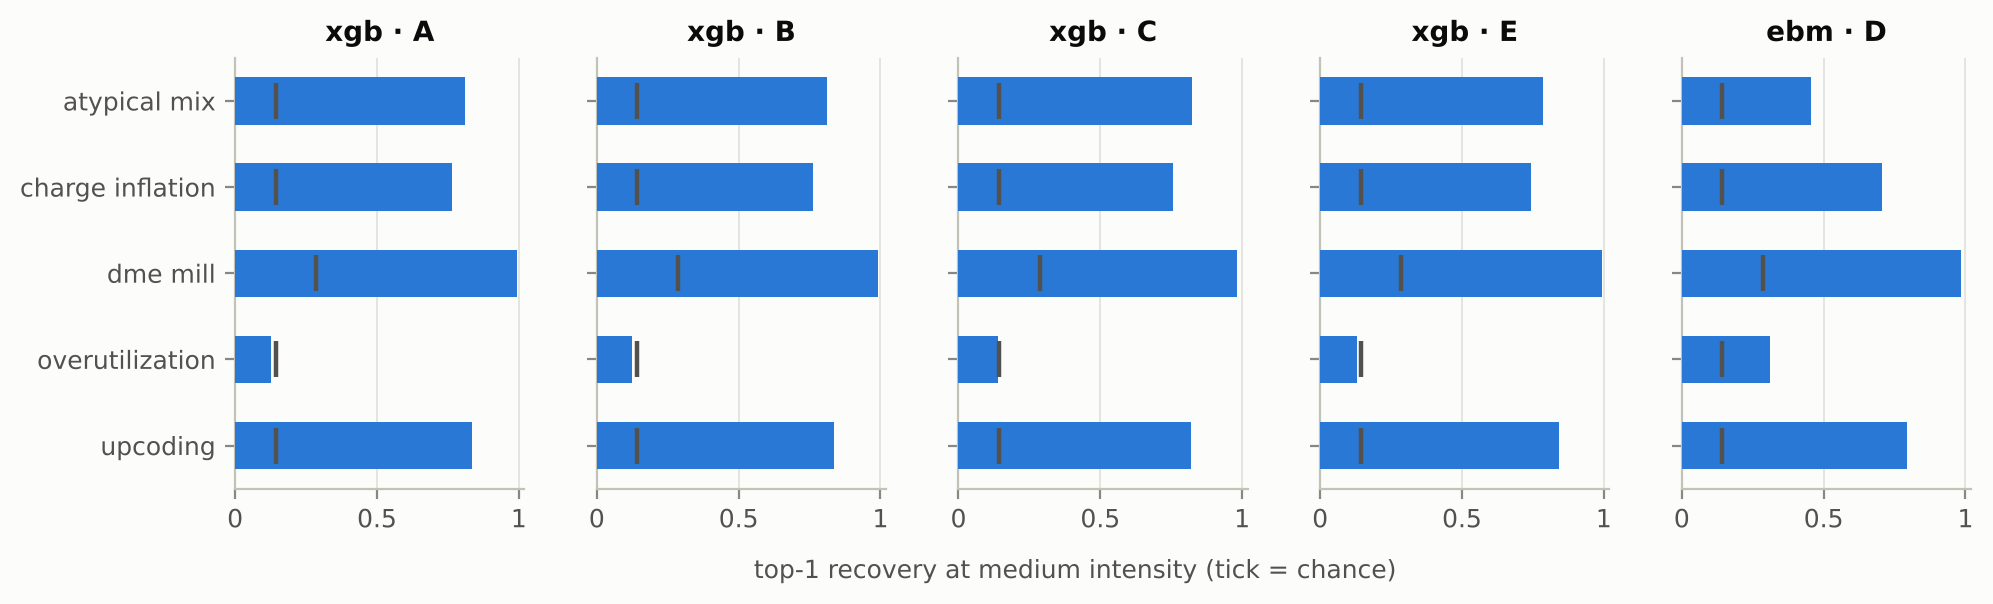

In [5]:
display(table("T2_correctness"))
figure("F3_recovery", 1000)

family              ebm                  xgb              
intensity          high    low medium   high    low medium
schemes_key                                               
atypical_mix      0.329  0.592  0.457  0.765  0.852  0.812
charge_inflation  0.822  0.536  0.707  0.867  0.560  0.761
dme_mill          0.995  0.973  0.985  0.995  0.977  0.993
overutilization   0.181  0.355  0.309  0.089  0.181  0.123
upcoding          0.713  0.727  0.795  0.789  0.787  0.837

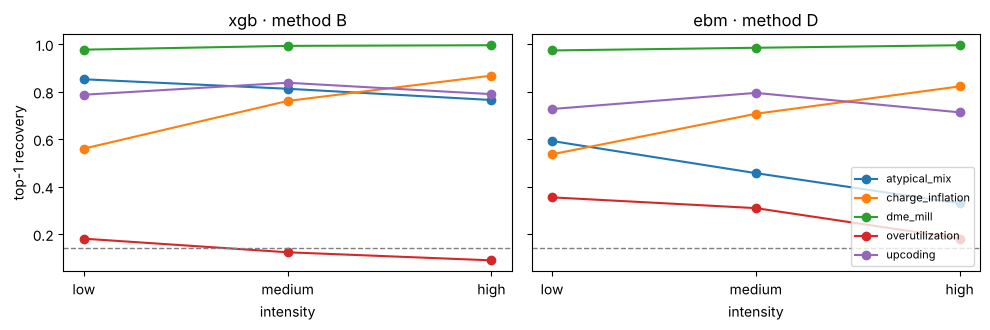

In [6]:
cr = load("phase6/correctness.json")
bsi = pd.DataFrame(cr["by_scheme_intensity"])
sel = bsi[((bsi.family == BEST["gbm"]) & (bsi.method == "B")) | ((bsi.family == BEST["glass_box"]) & (bsi.method == "D"))]
single = sel[~sel.schemes_key.str.contains(r"\+")]
piv = single.pivot_table(index="schemes_key", columns=["family", "intensity"], values="top1")
display(piv.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
order = ["low", "medium", "high"]
for ax, (fam, meth) in zip(axes, [(BEST["gbm"], "B"), (BEST["glass_box"], "D")]):
    d = single[(single.family == fam) & (single.method == meth)]
    for s, g in d.groupby("schemes_key"):
        g = g.set_index("intensity").reindex(order)
        ax.plot(order, g["top1"], marker="o", label=s)
    ax.axhline(single["chance_top1"].iloc[0], color="grey", lw=1, ls="--")
    ax.set_title(f"{fam} · method {meth}")
    ax.set_xlabel("intensity")
axes[0].set_ylabel("top-1 recovery")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

Spill-over: how much of the explanation lands on the answer group versus on spill-over groups that the scheme also moves.

In [7]:
sp = pd.DataFrame(cr["spill"])
display(sp[sp.family.isin([BEST["gbm"], BEST["glass_box"]])].pivot_table(index="schemes_key", columns=["family", "method"], values="answer_share").round(3))

family                          ebm                         xgb                     
method                            B      C      D      E      A      B      C      E
schemes_key                                                                         
atypical_mix                  0.384  0.384  0.384  0.384  0.686  0.687  0.692  0.655
charge_inflation              0.563  0.563  0.562  0.563  0.672  0.672  0.655  0.675
dme_mill                      0.853  0.853  0.853  0.853  0.915  0.915  0.826  0.930
overutilization               0.340  0.340  0.339  0.340  0.281  0.280  0.269  0.282
overutilization+atypical_mix  0.500  0.500  0.500  0.500  0.524  0.525  0.559  0.481
overutilization+dme_mill      0.815  0.815  0.815  0.815  0.853  0.854  0.753  0.900
upcoding                      0.572  0.572  0.572  0.572  0.691  0.689  0.655  0.706
upcoding+charge_inflation     0.767  0.767  0.767  0.767  0.846  0.844  0.828  0.835
upcoding+overutilization      0.595  0.595  0.595  0.595  0.579  0.583  0.568  0.583

Every single scheme is recovered well above chance (0.171) except **overutilization**. The best GBM ranks it first less often than chance (0.12 at medium intensity), and EBM only about 0.31 of the time. Most of its attribution lands outside the answer group: the answer share is 0.28 for the GBM.

Averaged over schemes, recovery changes little with intensity, because the intensities were calibrated so that the primary feature lands in the peer tail (D129). Individual schemes do move, in opposite directions: charge inflation is found more often at higher intensity, atypical mix less often. The glass boxes' own terms (method D) recover the schemes somewhat less well than the GBM's group attributions (T2). Pairs of schemes are rarely identified as a pair: the pair hit is 0.03–0.05 against 0.06 by chance.

## 4. Detection stress test (use a)

Here the main models, trained on clean data, score the injected providers. The question is whether a fraud scheme pushes a provider into the flagged top k.

family,ebm,ga2m,lgbm,lgbm_mono,lr,xgb,xgb_mono
schemes_key,,,,,,,
atypical_mix,0.620,0.630,0.650,0.645,0.631,0.628,0.637
charge_inflation,0.449,0.441,0.477,0.532,0.451,0.465,0.539
dme_mill,0.956,0.962,0.983,0.982,0.985,0.938,0.972
overutilization,0.781,0.803,0.854,0.882,0.790,0.803,0.841
overutilization+atypical_mix,0.809,0.835,0.868,0.890,0.826,0.812,0.865
overutilization+dme_mill,0.990,0.990,0.992,0.996,0.996,0.975,0.993
upcoding,0.562,0.566,0.506,0.587,0.629,0.477,0.586
upcoding+charge_inflation,0.467,0.451,0.464,0.583,0.555,0.408,0.604
upcoding+overutilization,0.782,0.787,0.830,0.879,0.839,0.754,0.843


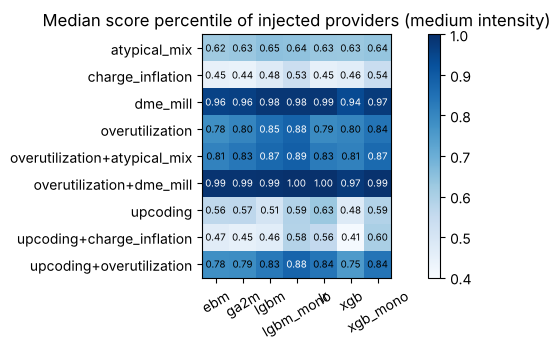

family,ebm,ga2m,lgbm,lgbm_mono,lr,xgb,xgb_mono
schemes_key,,,,,,,
atypical_mix,0.013,0.017,0.013,0.017,0.018,0.011,0.013
charge_inflation,0.004,0.003,0.006,0.009,0.004,0.007,0.012
dme_mill,0.232,0.282,0.378,0.417,0.427,0.212,0.310
overutilization,0.025,0.029,0.029,0.049,0.024,0.027,0.048
overutilization+atypical_mix,0.037,0.045,0.038,0.047,0.032,0.040,0.067
overutilization+dme_mill,0.499,0.503,0.539,0.628,0.697,0.335,0.582
upcoding,0.010,0.007,0.012,0.019,0.011,0.009,0.018
upcoding+charge_inflation,0.006,0.005,0.006,0.018,0.012,0.005,0.015
upcoding+overutilization,0.040,0.034,0.031,0.066,0.048,0.022,0.061


In [8]:
st = pd.DataFrame(load("phase6/stress.json")["summary"])
med = st[st.intensity == "medium"].pivot_table(index="schemes_key", columns="family", values="median_percentile")
display(med.round(3))
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(med.values, cmap="Blues", vmin=0.4, vmax=1)
ax.set_xticks(range(med.shape[1]), med.columns, rotation=30)
ax.set_yticks(range(med.shape[0]), med.index)
for i in range(med.shape[0]):
    for j in range(med.shape[1]):
        ax.text(j, i, f"{med.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if med.values[i, j] > 0.85 else "black")
ax.set_title("Median score percentile of injected providers (medium intensity)")
plt.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout()
plt.show()
display(st[st.intensity == "medium"].pivot_table(index="schemes_key", columns="family", values="in_top_0.01").round(3))

Only DME-mill schemes, alone or combined, reliably push providers toward the top of the ranking. At a 1 % flag rate, upcoding and charge inflation are mostly missed. The models learned what the LEIE labels reflect, not every scheme.

## 5. Consistency with the glass boxes (RQ2; table T3, figure F4)

These are providers flagged by both the best GBM and the glass box at k = 1 %. The permutation baseline pairs each provider with a random other provider in the same stratum.

,GBM method,vs,n,Sign agree,Spearman ρ,Top-3 Jaccard,Share cos,Permutation baseline (cos),Magnitude ratio
0,xgb · A,ebm,9018,1.000,0.857,0.5,0.951,0.657,1.167
1,xgb · B,ebm,9018,1.000,0.857,0.5,0.950,0.656,1.165
2,xgb · C,ebm,9018,1.000,0.857,1.0,0.956,0.668,1.221
3,xgb · E,ebm,9018,0.857,0.786,0.5,0.902,0.599,1.169
4,xgb · A,ga2m,8867,1.000,0.857,0.5,0.943,0.667,1.121
5,xgb · B,ga2m,8867,1.000,0.857,0.5,0.942,0.666,1.120
6,xgb · C,ga2m,8867,1.000,0.857,0.5,0.948,0.679,1.163
7,xgb · E,ga2m,8867,0.857,0.750,0.5,0.895,0.609,1.136


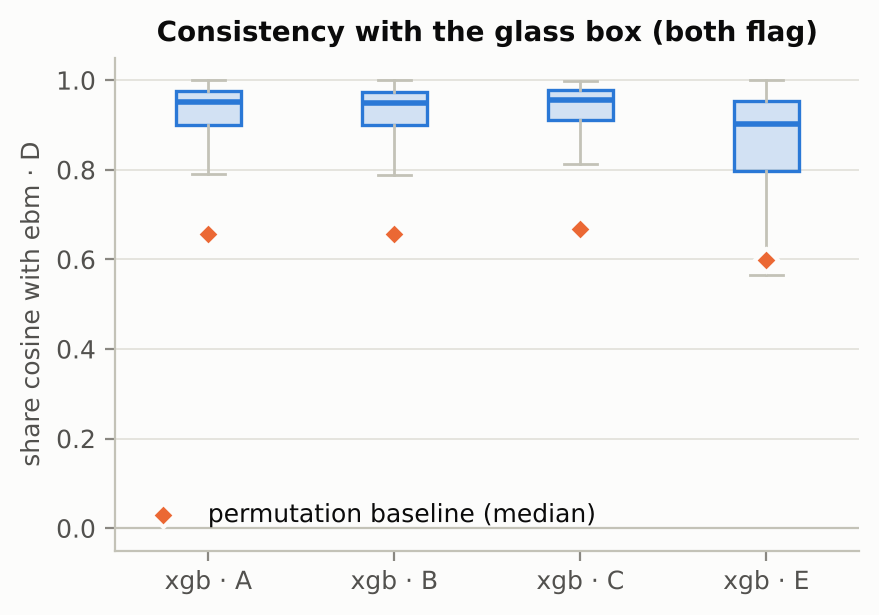

In [9]:
display(table("T3_consistency"))
figure("F4_consistency", 520)

In [10]:
co = load("phase6/consistency.json")
rows = [{"gbm": e["gbm"], "method": e["method"], "glass_box": e["glass_box"], "stratum": e["stratum"], "n": e["n"],
         "cosine": e["cosine"]["median"], "perm_cosine": e["cosine"]["perm_median"]}
        for e in co["summary"] if "cosine" in e]
cs = pd.DataFrame(rows)
display(cs[(cs.method == "B")].pivot_table(index=["glass_box", "stratum"], values=["n", "cosine", "perm_cosine"]).round(3))

cosine         n  perm_cosine
glass_box stratum                                      
ebm       all              0.890  51276.00        0.370
          both             0.933   7865.00        0.682
          gbm_only         0.910   6977.00        0.574
          glass_box_only   0.889   4760.00        0.509
          neither          0.868  31674.00        0.164
ga2m      all              0.885  51276.00        0.379
          both             0.928   7765.75        0.692
          gbm_only         0.906   7076.25        0.579
          glass_box_only   0.880   4604.25        0.519
          neither          0.863  31829.75        0.168
lr        all              0.818  51276.00        0.279
          both             0.896   6373.25        0.659
          gbm_only         0.837   8468.75        0.472
          glass_box_only   0.859   3726.75        0.504
          neither          0.776  32707.25        0.087

## 6. Faithfulness and stability (RQ4; table T4, figure F5)

The deletion score is the area under the normalised group-deletion curve, removing groups in the method's order; lower is more faithful. It is compared with random and reverse orders and reported as medians (D104). Stability covers three things on 2,000 providers:
- agreement on the top-1 group across 10 seeds;
- across 10 bootstrap retrains;
- across 10 input perturbations.

,model · method,n,Deletion ↓ (median),Random order (median),Reverse order (median),Share below random,Top-1 agree (seeds),Kendall τ (seeds),Top-1 agree (bootstrap),Kendall τ (bootstrap),Top-1 agree (perturbation)
0,lr · B,41501,0.006,0.505,0.994,1.000,0.991,0.992,0.743,0.718,0.970
1,lr · C,41501,0.006,0.505,0.994,1.000,0.991,0.992,0.743,0.718,0.970
2,lr · D,41501,0.006,0.505,0.994,1.000,0.991,0.992,0.733,0.702,0.970
3,lr · E,41501,0.006,0.505,0.994,1.000,0.991,0.992,0.743,0.718,0.970
4,ebm · B,44671,0.106,0.500,0.894,1.000,0.908,0.916,0.727,0.666,0.970
5,ebm · C,44671,0.106,0.500,0.894,1.000,0.908,0.916,0.727,0.666,0.970
6,ebm · D,44671,0.106,0.500,0.894,1.000,0.907,0.894,0.726,0.652,0.970
7,ebm · E,44671,0.106,0.500,0.894,1.000,0.908,0.916,0.727,0.666,0.970
8,ga2m · B,44549,0.111,0.506,0.899,1.000,0.886,0.890,0.685,0.616,0.976
9,ga2m · C,44549,0.111,0.506,0.894,1.000,0.889,0.897,0.684,0.624,0.975


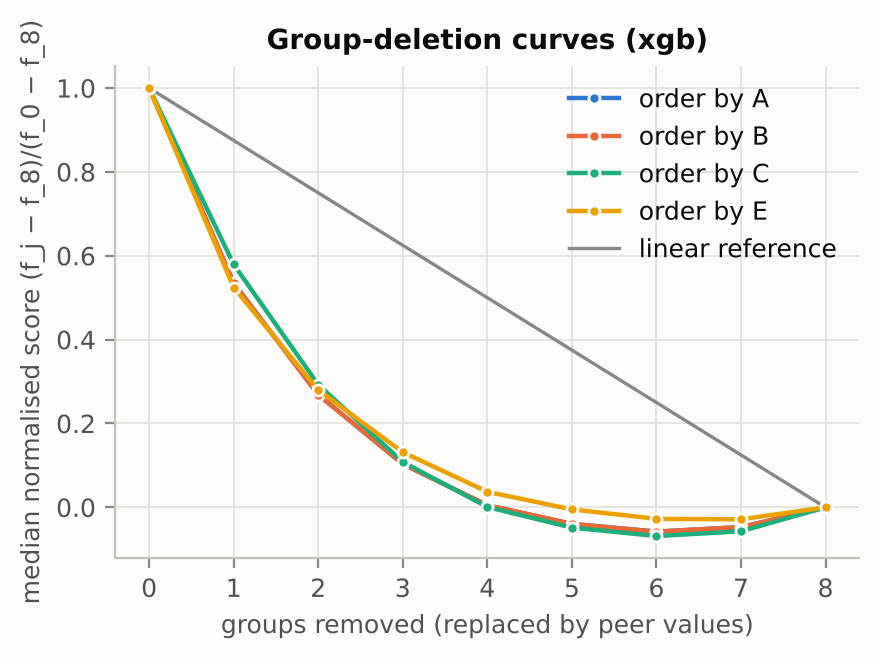

In [11]:
display(table("T4_faithfulness_stability"))
figure("F5_deletion_curves", 520)

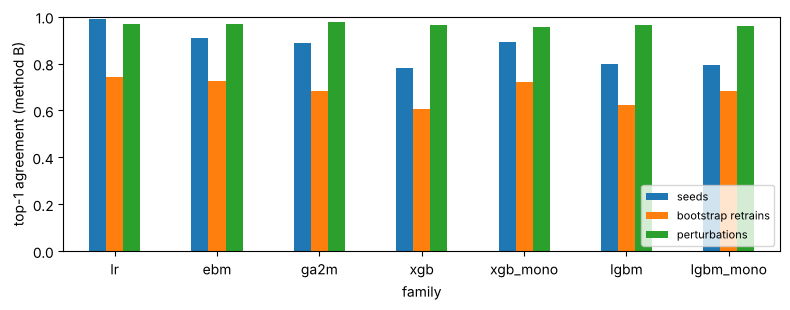

In [12]:
stab = load("phase6/stability.json")
rows = [{"family": f, **r} for f, v in stab["families"].items() for r in v["summary"]]
sb = pd.DataFrame(rows)
b = sb[sb.method == "B"].set_index("family")[["top1_agree_seed", "top1_agree_boot", "top1_agree_perturb"]]
ax = b.plot.bar(figsize=(8, 3.2), rot=0)
ax.set_ylabel("top-1 agreement (method B)")
ax.set_ylim(0, 1)
ax.legend(["seeds", "bootstrap retrains", "perturbations"], fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

Every method deletes far better than random order: the share of providers below their random-order score is about 1.0 for all. Across seeds, LR, EBM, GA²M and monotone XGBoost are the most stable, agreeing on the top-1 group 0.89–0.99 of the time. Plain XGBoost and both LightGBMs sit at about 0.78–0.80. Across bootstrap retrains every family is less stable, from 0.61 (XGBoost) to 0.74 (LR). Perturbing the inputs changes little, about 0.96 or higher for all.

## 7. Global scheme importance and an interaction matrix (figures F2, F6)

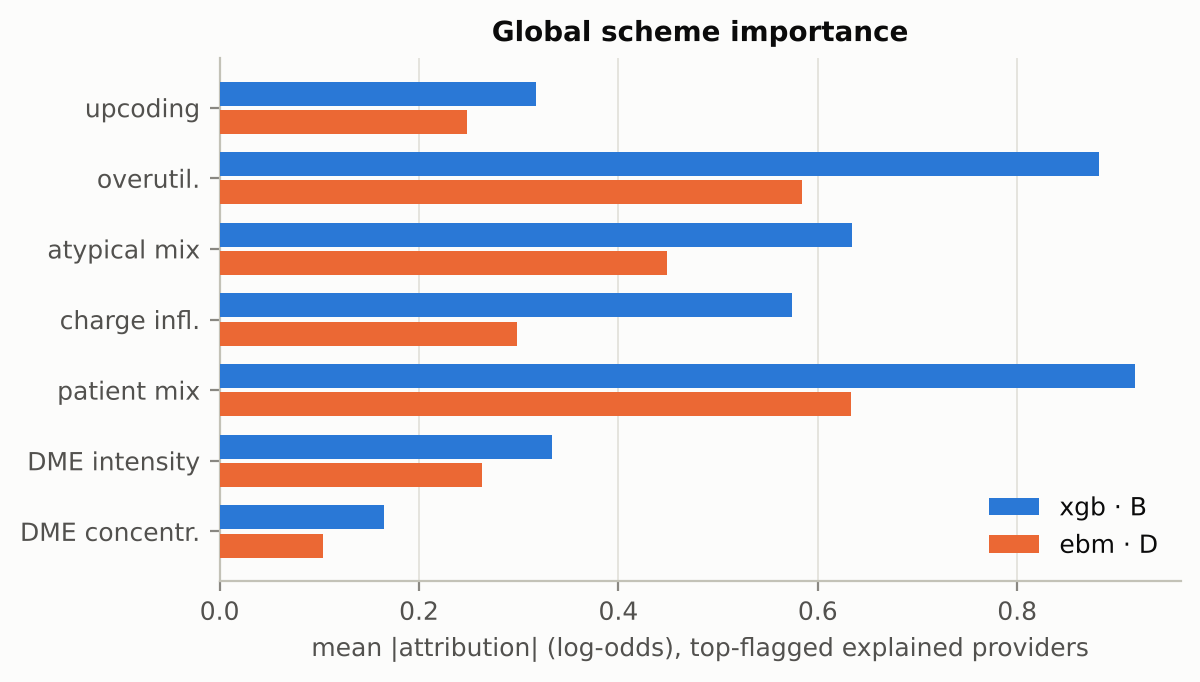

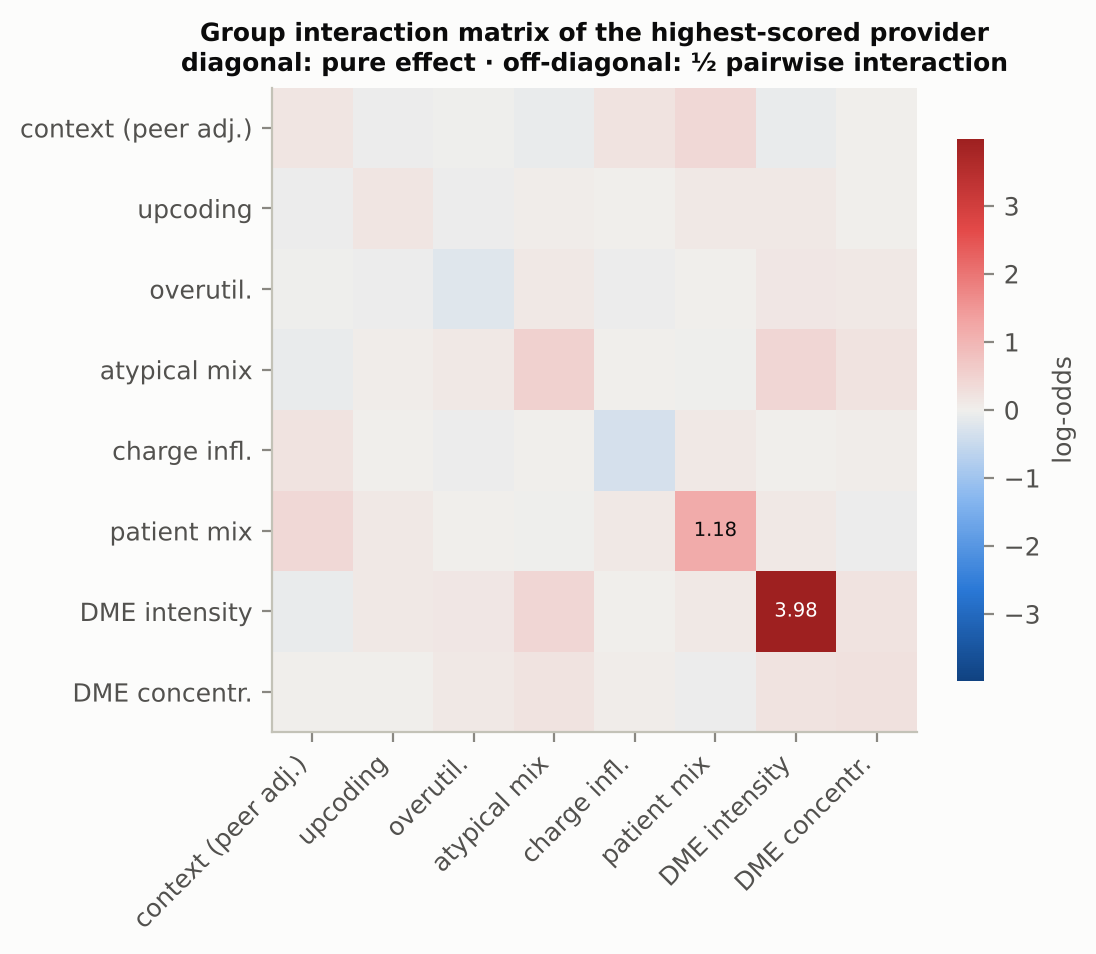

In [13]:
figure("F2_scheme_importance", 640)
figure("F6_interaction_matrix", 600)

## 8. Peer vs global baseline (RQ5; figure F7)

What changes when the reference is all providers instead of the provider's own peer cell?

,family,method,n,context_share_peer,context_share_global,context_top_peer,context_top_global,top1_agreement,spearman_median,cosine_median
0,xgb,A,51276,0.110,0.163,0.092,0.194,0.838,0.929,0.982
1,xgb,B,51276,0.110,0.164,0.092,0.196,0.837,0.929,0.982
2,xgb,E,51276,0.112,0.163,0.092,0.186,0.862,0.964,0.987


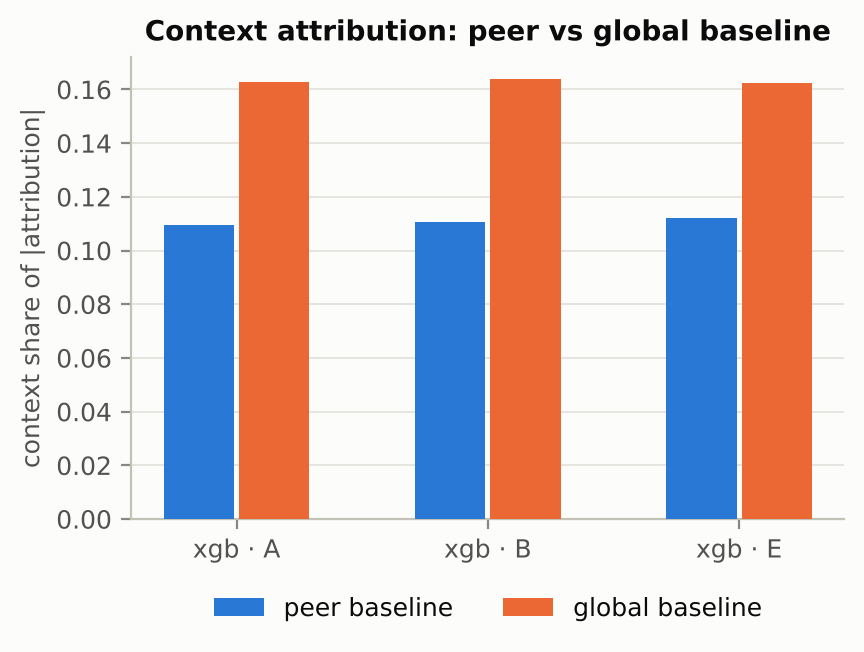

In [14]:
bl = load("phase6/baselines.json")
display(pd.DataFrame(bl["summary"]).round(3))
figure("F7_peer_vs_global", 520)

With a global baseline the context group (specialty, entity type, region) absorbs about half again as much attribution: 0.16 instead of 0.11 of the total. The top-1 group still agrees for about 84 % of providers. The peer baseline keeps explanations about behaviour relative to comparable providers.

## 9. Sensitivity suite (E9; table T5)

Each variant changes one protocol choice and reruns the affected stages. The table compares each variant with the main run's best GBM, method B. S1_W1 (W = 1) is not estimable: one fold has no validation positives (D134).

In [15]:
display(table("T5_sensitivity"))

,Variant,Description,PR-AUC (variant),PR-AUC (main),Top-1 agree with main (B),Share cos vs glass box (B),Top-1 injected (B)
0,S10,peer cells without region,0.001,0.002,0.635,0.896,–
1,S11,prior-work-compatible label tier,0.002,0.002,0.628,0.890,–
2,S12,negative subsampling 30 %,0.001,0.002,0.778,0.815,–
3,S13,primary tier + unsplit 1128(b)(1) (G1 decision...,0.002,0.002,0.773,0.906,–
4,S1_W1,label window W = 1 (not estimable: primary fol...,–,–,–,–,–
5,S1_W2,label window W = 2,0.000,0.002,0.632,0.889,–
6,S1_W5,label window W = 5,0.002,0.002,0.632,0.908,–
7,S2,broad label tier,0.001,0.002,0.663,0.905,–
8,S3,individuals only,0.001,0.002,0.749,0.894,–
9,S4,exclude 2020,0.001,0.002,0.711,0.899,–


In [16]:
rows = []
for f in sorted((OUT / "phase6" / "sensitivity").glob("*.json")):
    r = json.loads(f.read_text())
    fa = next((x for x in r.get("faithfulness", []) if x["family"] == BEST["gbm"] and x["method"] == "B"), None)
    rows.append({"variant": r["variant"], "what": r.get("what"), "not_estimable": r.get("not_estimable"),
                 "deletion_median_B": fa and round(fa["median"], 3)})
display(pd.DataFrame(rows))

,variant,what,not_estimable,deletion_median_B
0,S10,peer cells without region,NaN,0.136
1,S11,prior-work-compatible label tier,NaN,0.129
2,S12,negative subsampling 30 %,NaN,0.147
3,S13,primary tier + unsplit 1128(b)(1) (G1 decision...,NaN,0.146
4,S1_W1,label window W = 1,primary fold 0: tune_valid has 0 positives (< ...,NaN
5,S1_W2,label window W = 2,NaN,0.124
6,S1_W5,label window W = 5,NaN,0.140
7,S2,broad label tier,NaN,0.129
8,S3,individuals only,NaN,0.152
9,S4,exclude 2020,NaN,0.142


## 10. Fairness profile (E10; table T6, figure F8)

This section is descriptive. It shows flag rate, precision, and the ratio of flag rate to positive rate by entity type, rurality, Census division and specialty. The LEIE reflects enforcement patterns, which limits interpretation (DESIGN §10.7).

,Attribute,Value,k,N,Positives,Flagged,Flag rate,Precision,Flag ÷ positive rate
17,ent_cd,I,1.0%,1955047,185,19762,0.0101,0.001,106.82
18,ent_cd,O,1.0%,119055,9,980,0.0082,0.000,108.89
19,census_division,South Atlantic,1.0%,422468,25,3728,0.0088,0.001,149.12
20,census_division,East North Central,1.0%,324719,30,3957,0.0122,0.001,131.90
21,census_division,Middle Atlantic,1.0%,312139,27,3234,0.0104,0.001,119.78
22,census_division,Pacific,1.0%,245587,26,3031,0.0123,0.002,116.58
23,census_division,West South Central,1.0%,206029,31,2901,0.0141,0.001,93.58
24,census_division,West North Central,1.0%,157197,20,969,0.0062,0.000,48.45
25,census_division,Mountain,1.0%,143411,11,835,0.0058,0.004,75.91
26,census_division,New England,1.0%,130066,6,507,0.0039,0.000,84.50


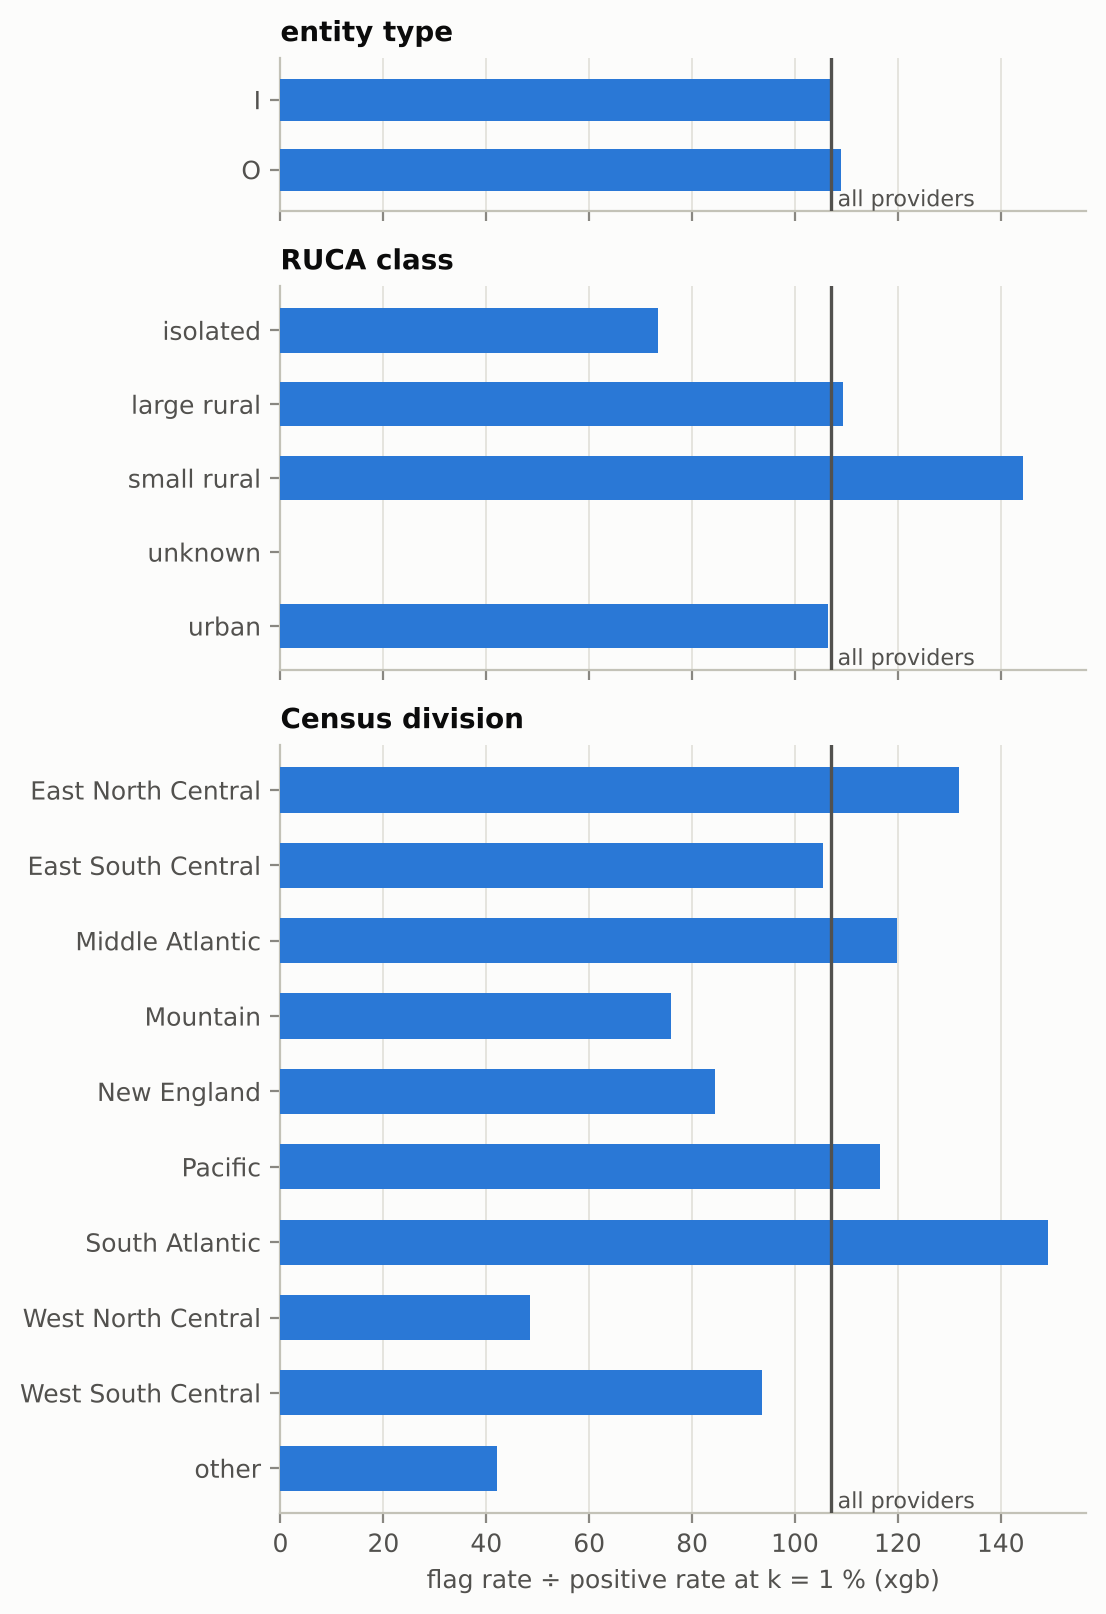

In [17]:
t6 = table("T6_fairness")
display(t6[t6["k"] == "1.0%"])
figure("F8_fairness", 560)

## 11. Conclusion and reproducibility

The DESIGN §10.8 row the results are consistent with (rule D108). The authors chose it in D137.

In [18]:
br = ev["branch"]
display(Markdown(f"- H1 (GBM beats glass box) supported: **{br['h1_supported']}**\n"
                 f"- Best GBM's method-{br['method']} explanations correct on injected schemes: **{br['correct']}**\n"
                 f"- Consistent with EBM and GA²M: **{br['consistent']}**\n\n"
                 f"**Branch:** {br['row']}"))
rep = load("phase7/reproducibility.json")
print("git commit:", rep["git_commit"], "| dirty:", rep["git_dirty"], "| python:", rep["python"])
print("packages:", {k: rep["packages"][k] for k in list(rep["packages"])[:12]})
print("seeds:", rep["seeds"])

- H1 (GBM beats glass box) supported: **False**
- Best GBM's method-B explanations correct on injected schemes: **True**
- Consistent with EBM and GA²M: **True**

**Branch:** "No significant difference": recommend the glass box; the scenario framework and method comparison stand.

git commit: 2d53bab1880ddba18e74be2e3cffbb1e1fcdea06 | dirty: False | python: 3.13.16
packages: {'numpy': '2.5.4', 'pandas': '3.0.6', 'pyarrow': '26.0.0', 'polars': '2.0.0', 'duckdb': '1.5.6', 'pyyaml': '6.0.3', 'requests': '2.34.2'}
seeds: {'experiment': {'splits.seed': 20261013, 'splits.negative_subsample.seed': 20261014, 'evaluation.bootstrap_seed': 20261016}, 'models': {'tuning_seed': 20261015}, 'attribution': {'seed': 20261017, 'reference_seed': 0}, 'injection': {'seed': 20261018}, 'evaluation': {'seed': 20261019}, 'views': {'seed': 20261020}}


To rerun everything from raw data, follow `outputs/phase7/REPRODUCE.md`, which takes days of compute. The data used here is archived outside the repository. The paper outline with these tables inserted is `outputs/phase7/draft.md`; LaTeX tables are in `outputs/phase7/tables/*.tex` and vector figures in `outputs/phase7/figures/*.pdf`.